In [1]:
import torch
import torchvision
from torchvision.datasets import MNIST

In [2]:
from torchvision import transforms as T

In [3]:
tfs = T.Compose([T.Resize((28, 28)), T.Grayscale(num_output_channels=3), T.ToTensor()] ) # Resize rasmni 28 x 28 ga o'zgartiradi, Grayscale ->Kulrang rasmни 3 ta bir xil grayscale kanal bilan ifodalaydi., ToTensor -> tensor formatiga o'tkazadi

ds = MNIST(root="datasets", train=True, download=True, transform = tfs)
ts_ds = MNIST(root="datasets", train=False, download=True, transform = tfs)

In [4]:
classes = ds.classes
n_cls = len(classes)
n_train = len(ds)
n_cls
# bu yerda biz MNIST datasetidagi sinflar sonini va train datasetdagi rasm sonini hisoblayapmiz.

10

In [5]:
# Datamizni ajratib olish uchun quyidagi kodni yozamiz.
from torch.utils.data import random_split, DataLoader # bu yerda biz train datasetni train va validation ga bo'lish uchun random_split va DataLoader import qilamiz.
total_train = len(ds) # bu yerda train datasetdagi rasm sonini hisoblayapmiz
tr_len = int(total_train * 0.8) # bu yerda train datasetni 80% train va 20% validation ga bo'lamiz.
vl_len = total_train - tr_len # bu yerda validation datasetdagi rasm sonini hisoblayapmiz.
tr_len, vl_len # bu yerda train va validation datasetdagi rasm sonini chiqaramiz.

(48000, 12000)

In [6]:
tr_ds, vl_ds = random_split(dataset= ds, lengths=[tr_len, vl_len]) # bu yerda train datasetni train va validation ga bo'lamiz.
print(f"Train datasetimiz: {len(tr_ds)}") # bu yerda train datasetdagi rasm sonini chiqaramiz.
print(f"Validation datasetimiz: {len(vl_ds)}") # bu yerda validation datasetdagi rasm sonini chiqaramiz.

Train datasetimiz: 48000
Validation datasetimiz: 12000


In [7]:
bs = 64 # batch size
tr_dl = DataLoader(dataset=tr_ds, batch_size=bs, shuffle=True, num_workers=2) # bu yerda train datasetni DataLoader ga o'tkazamiz.
vl_dl = DataLoader(dataset=vl_ds, batch_size=bs, shuffle=False, num_workers=2) # bu yerda validation datasetni DataLoader ga o'tkazamiz.
ts_dl = DataLoader(dataset=ts_ds, batch_size=bs, shuffle=False, num_workers=2) # bu yerda test datasetni DataLoader ga o'tkazamiz.

In [ ]:
# Cross Entropy Loss — neyron tarmoq bashorati (prediction) bilan haqiqiy javob (target) o‘rtasidagi farqni o‘lchaydigan loss function.
# Uning asosiy vazifasi — model noto‘g‘ri bashorat qilganda xatolikni hisoblash va modelni o‘qitish davomida ushbu xatolikni kamaytirishga yordam berish.

# Modelni yaratib olamiz!

In [8]:
import torch
from torch.nn import *

# Modelni yaratish
class CustomModel(Module):
    def __init__(self, in_features, out_fs, n_cls):
        super().__init__()
        self.lin_layer = Linear(in_features=in_features, out_features=out_fs)
        self.act = ReLU()
        self.classifier = Linear(in_features=out_fs, out_features=n_cls)
       

    def forward(self, input):
        bs = input.shape[0]  # Get the batch size
        input = input.view(bs, -1)  # linierimizni ishlashi uchun inputni 2D ga o'zgartiramiz. (bs, in_features) ga o'zgartiramiz.

        out = self.lin_layer(input)
        out = self.act(out)
        out = self.classifier(out)

        return out

input = torch.randn(1, 3, 28, 28)  # Example input tensor with shape (batch_size, channels, height, width)
out_fs = 200
n_cls = 10  # Example number of classes

m = CustomModel(in_features=input.shape[1] * input.shape[2] * input.shape[3], out_fs=out_fs, n_cls=n_cls)
xom_bashorat = m(input)
#xom_bashorat.shape  # This will give you the shape of the output tensor
xom_bashorat
      

tensor([[ 0.0609,  0.0081, -0.1098, -0.0323,  0.0161, -0.2917,  0.0155, -0.3912,
          0.4072,  0.0989]], grad_fn=<AddmmBackward0>)

In [9]:
softmax = torch.nn.Softmax(dim=1)

In [10]:
loss_fn = CrossEntropyLoss() # bu yerda CrossEntropyLoss ni import qilamiz.

In [11]:
optimizer = torch.optim.Adam(params=m.parameters(), lr=3e-4) # bu yerda Adam optimizer ni import qilamiz.

In [12]:
eps = 1e-10 # bu yerda eps ni import qilamiz. (eps - bu juda kichik son, u log(0) ni oldini olish uchun ishlatiladi.)
1 / (0 + eps) # bu yerda eps ni ishlatib log(0) ni oldini olish uchun ishlatiladi.

10000000000.0

In [13]:
label = torch.stack([torch.tensor(4), torch.tensor(5), torch.tensor(2), torch.tensor(1)]) # bu yerda label ni yaratamiz.
bashoratlar = torch.stack([torch.tensor(4), torch.tensor(0), torch.tensor(1), torch.tensor(1)]) # bu yerda bashoratlar ni yaratamiz.
(label == bashoratlar).sum().item() # bu yerda label va bashoratlar o'rtasidagi to'g'ri bashoratlar sonini hisoblaymiz va ularni label soniga bo'lamiz.



2

In [14]:
epochs = 10 
for epoch in range(epochs):
    if epoch == 1:break
    epoch_acc = 0
    epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

for idx, batch in enumerate(tr_dl):
        
    if idx == 4: break
    rasmlar, label = batch
    #print(f"rasmlar: {rasmlar.shape}, label: {label.shape}")
    
    xom_ba = m(rasmlar)
    bashoratlar = torch.argmax(xom_ba, dim = 1)

    loss = loss_fn(xom_ba, label)
    # print(loss)

    optimizer.zero_grad()
    loss.backward()
    epoch_loss += loss.item()
    print(f"Epoch: {epoch}, Batch: {idx}, Loss: {loss.item()}")

    optimizer.step()

    batch_acc = (bashoratlar == label).float().mean()
    epoch_acc += batch_acc
    
    print(f"{epoch + 1}-epochdagi train loss -> {epoch_loss / len(tr_dl):.3f}") # batch soniga bo'linadi
    print(f"{epoch + 1}-epochdagi train acc  -> {epoch_acc / len(tr_dl):.3f}") 
    # print(bashoratlar)
    # print(label)
with torch.no_grad():

    for idx, batch in enumerate(vl_dl):
        
        if idx == 4: break
        rasmlar, label = batch
    #print(f"rasmlar: {rasmlar.shape}, label: {label.shape}")
    
        xom_ba = m(rasmlar)
        bashoratlar = torch.argmax(xom_ba, dim = 1)
        loss = loss_fn(xom_ba, label)
        vl_epoch_loss += loss.item()
        batch_acc = (bashoratlar == label).float().mean()
        vl_epoch_acc += batch_acc
    
    print(f"{epoch + 1}-epochdagi train loss -> {vl_epoch_loss / len(vl_dl):.3f}") # batch soniga bo'linadi
    print(f"{epoch + 1}-epochdagi train acc  -> {vl_epoch_acc / len(vl_dl):.3f}")

Epoch: 1, Batch: 0, Loss: 2.3036258220672607
2-epochdagi train loss -> 0.003
2-epochdagi train acc  -> 0.000
Epoch: 1, Batch: 1, Loss: 2.2710132598876953
2-epochdagi train loss -> 0.006
2-epochdagi train acc  -> 0.000
Epoch: 1, Batch: 2, Loss: 2.2042739391326904
2-epochdagi train loss -> 0.009
2-epochdagi train acc  -> 0.001
Epoch: 1, Batch: 3, Loss: 2.1777403354644775
2-epochdagi train loss -> 0.012
2-epochdagi train acc  -> 0.002
2-epochdagi train loss -> 0.045
2-epochdagi train acc  -> 0.012


In [15]:
m.eval()
test_loss = 0
test_acc = 0
with torch.no_grad():
    for idx, batch in enumerate(ts_dl):
        if idx == 4: break
        rasmla, label = batch
        xom_ba = m(rasmla)
        bashoratlar = torch.argmax(xom_ba, dim=1)
        
        loss = loss_fn(xom_ba, label)
        test_loss += loss.item()

        batch_acc = (bashoratlar == label).sum().item()
        test_acc += batch_acc
print(f"{epoch + 1}-epochdagi Test Loss: {test_loss/len(ts_dl):.3f}")
print(f"{epoch + 1}-epochdagi Test Accuracy: {test_acc/len(ts_dl):.3f}")

2-epochdagi Test Loss: 0.055
2-epochdagi Test Accuracy: 0.898


# Fashion MNIST Dataset Deep Learning

In [16]:
import torch 
import torchvision
from torchvision.datasets import FashionMNIST
from torchvision import transforms as T

tfs = T.Compose( [T.Resize((28, 28)), T.Grayscale(num_output_channels = 3), T.ToTensor()] )

train_ds = FashionMNIST(root='./data', train=True, download=True, transform=tfs)
test_ds = FashionMNIST(root='./data', train=False, download=True, transform=tfs)

classes = train_ds.classes
print("Classes:", classes)
n_cls = len(classes)

Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [17]:
len(train_ds), len(test_ds)

(60000, 10000)

In [18]:
# DataLoader yaratish
from torch.utils.data import DataLoader
batch_size = 64
total_train = len(train_ds)
tr_len = int(total_train * 0.8)
vl_len = total_train - tr_len
tr_len, vl_len
tr_ds, vl_ds = random_split(dataset=train_ds, lengths=[tr_len, vl_len])


train_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)
vl_loader = DataLoader(vl_ds, batch_size=batch_size, shuffle=False)
ts_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

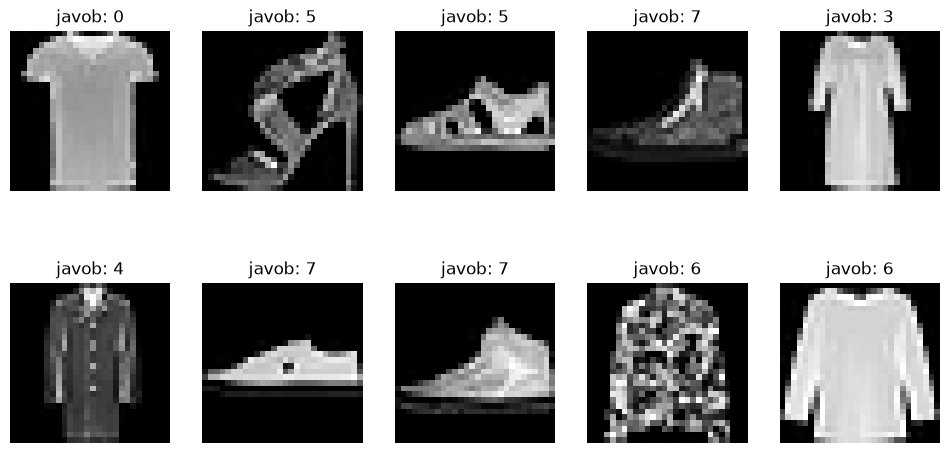

In [26]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(2, 5, figsize=(12, 6))
for i in range(2):
    for j in range(5):
        idx = np.random.randint(len(train_ds))
        rasm, javob = train_ds[idx]
        ax[i, j].imshow(rasm.permute(1, 2, 0).squeeze(), cmap='gray')
        ax[i, j].set_title(f"javob: {javob}")
        ax[i, j].axis('off')
plt.show()

In [27]:
from torch.nn import *
class CustomModel(Module):
    def __init__(self, in_fs, out_fs, n_clas):
        super().__init__()

        self.lin_layer = Linear( in_features=in_fs, out_features=out_fs)
        self.act = ReLU()
        self.classifier = Linear(in_features=out_fs, out_features=n_clas)

    def forward(self, inp):
        bs = inp.shape[0]
        inp = inp.view(bs, -1)  # linierrimiz 4d rasmni 2d rasmga o'zgartiradi

        out = self.lin_layer(inp)
        out = self.act(out)
        out = self.classifier(out)

        return out

inp = torch.randn(1, 3, 28, 28)
out_fs = 256
n_cls = 10

m = CustomModel(in_fs=inp.shape[1] * inp.shape[2] * inp.shape[3], out_fs=out_fs, n_clas=n_cls)
xom_bash = m(inp)

In [28]:
loss_fn = CrossEntropyLoss() # bu yerda CrossEntropyLoss ni import qilamiz.
optimizer = torch.optim.Adam(params=m.parameters(), lr=3e-4) # bu yerda Adam optimizer ni import qilamiz.

In [29]:
epochs = 11

for epoch in range(epochs):
    tr_epoch_loss = 0
    tr_epoch_acc = 0
    vl_epoch_loss = 0
    vl_epoch_acc = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javab = batch
        xom_ba = m(rasm)
        bashoratlar = torch.argmax(xom_ba, dim=1)
        loss = loss_fn(xom_ba, javab)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tr_epoch_loss += loss.item()
        batch_acc = (bashoratlar == javab).sum().item()
        tr_epoch_acc += batch_acc

print(f"{epoch + 1}-epochdagi train loss -> {tr_epoch_loss / len(tr_dl):.3f}") # batch soniga bo'linadi
print(f"{epoch + 1}-epochdagi train accuracy -> {tr_epoch_acc / len(tr_dl):.3f}") # batch soniga bo'linadi


with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javab = batch
            xom_ba = m(rasm)
            bashoratlar = torch.argmax(xom_ba, dim=1)
            loss = loss_fn(xom_ba, javab)
            vl_epoch_loss += loss.item()
            batch_acc = (bashoratlar == javab).sum().item()
            vl_epoch_acc += batch_acc

print(f"{epoch + 1}-epochdagi validation loss -> {vl_epoch_loss / len(vl_dl):.3f}") # batch soniga bo'linadi
print(f"{epoch + 1}-epochdagi validation accuracy -> {vl_epoch_acc / len(vl_dl):.3f}") # batch soniga bo'linadi

Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/usr/local/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.11/lib/python3.11/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.11/lib/python3.11/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/apple/Course/.venv311/lib/python3.11/site-packages/torch/multiprocessing/reductions.py", line 514, in rebuild_storage_filename
    storage = torch.UntypedStorage._new_shared_filename_cpu(manager, handle, size)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: Connection refused
Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/usr/local/Cellar/python

RuntimeError: DataLoader worker (pid(s) 5349) exited unexpectedly